```markdown
# Phase 1: Project Planning & Dataset Recommendation

## 1. Problem Statement
In subscription-based industries (like telecommunications), keeping existing customers is far more cost-effective than acquiring new ones. **Customer Churn** is the percentage of service subscribers who discontinue their subscriptions within a given time period. Our objective is to design, implement, and evaluate a predictive system that identifies customers at risk of churning, allowing proactive retention campaigns.

## 2. Machine Learning Workflow
To build a academically rigorous, portfolio-quality solution, we will implement this 7-step pipeline:
1. **Data Acquisition & Audit**: Load the IBM Telco Churn dataset and inspect columns, sizes, and data formats.
2. **Exploratory Data Analysis (EDA)**: Use Seaborn/Matplotlib to discover correlations, service configurations, and behavioral patterns.
3. **Data Preprocessing**: Build robust, leakage-free Scikit-Learn `Pipeline` and `ColumnTransformer` models to impute missing values, convert data types, encode categorical variables, and scale numeric features.
4. **Model Training**: Compare 6 classifiers: Logistic Regression, Decision Tree, Random Forest, Support Vector Machine (SVM), K-Nearest Neighbors (KNN), and Gradient Boosting.
5. **Model Evaluation & Tuning**: Evaluate models using ROC-AUC, Recall, F1-score, and optimize hyperparameters using stratified cross-validated Grid Search.
6. **Explainability**: Review model coefficients and Feature Importance to understand the primary drivers behind churn.
7. **Streamlit Deployment**: Export the preprocessing pipeline and optimal model to launch an interactive web dashboard.
```

In [1]:
# Import necessary libraries for Phase 2
import pandas as pd
import numpy as np

# URL of the raw IBM Telco Customer Churn Dataset
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

# Load the dataset
try:
    df = pd.read_csv(DATA_URL)
    print("✅ Dataset successfully loaded directly from source!")
    print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
except Exception as e:
    print(f"❌ Error loading dataset: {e}")

✅ Dataset successfully loaded directly from source!
Dataset Dimensions: 7043 rows, 21 columns



In [2]:
# Inspecting the schema, missing values, and column data types
print("--- Column Data Types & Missing Values Audit ---")
print(df.info())

print("\n--- First 3 Rows of the Dataset ---")
display(df.head(3))

--- Column Data Types & Missing Values Audit ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [3]:
# Class Imbalance Check (Target variable: 'Churn')
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

print("--- Class Distribution ---")
for idx, val in churn_counts.items():
    print(f"{idx}: {val} customers ({churn_pct[idx]:.2f}%)")

--- Class Distribution ---
No: 5174 customers (73.46%)
Yes: 1869 customers (26.54%)


```markdown
# Phase 4: Leakage-Free Data Preprocessing Pipeline

To construct an academically sound model, we must prevent **Data Leakage**. All preprocessing parameters (like mean, scale, or categorical categories) must be computed from the training split and only applied to the test split.
```

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. First, correct the TotalCharges data type issue by converting to numeric
# Empty spaces (' ') are coerced into NaN
df_cleaned = df.copy()
df_cleaned['TotalCharges'] = pd.to_numeric(df_cleaned['TotalCharges'].replace(' ', np.nan, regex=True))

# 2. Map Target Variable 'Churn' to binary integers (0 and 1)
df_cleaned['Churn'] = df_cleaned['Churn'].map({'Yes': 1, 'No': 0})

# 3. Drop unique identifiers that do not provide predictive patterns
X = df_cleaned.drop(columns=['customerID', 'Churn'])
y = df_cleaned['Churn']

# 4. Stratified Split to maintain class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set dimensions: {X_train.shape}")
print(f"Testing set dimensions: {X_test.shape}")
print(f"Training target distribution: {np.bincount(y_train)}")

Training set dimensions: (5634, 19)
Testing set dimensions: (1409, 19)
Training target distribution: [4139 1495]


In [5]:
# Define feature columns by type
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

# Numeric transformation pipeline: impute with median and scale to mean=0, std=1
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical transformation pipeline: one-hot encode
categorical_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

# Combine everything using ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("✅ Pipeline and ColumnTransformer defined successfully!")

✅ Pipeline and ColumnTransformer defined successfully!


```markdown
# Phase 7 & 8: Hyperparameter Tuning and Feature Importance Analysis

Now, we optimize the best-performing estimator via `GridSearchCV` and extract feature importances to interpret model decisions.
```

In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
import pickle

# 1. Instantiate the base pipeline with Gradient Boosting
tuning_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

# 2. Define our hyperparameter search space grid
param_grid = {
    'classifier__n_estimators': [50, 100, 150],
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__max_depth': [3, 4, 5]
}

# 3. Perform Grid Search with 3-Fold Stratified Cross Validation optimizing for ROC-AUC
grid_search = GridSearchCV(
    tuning_pipeline,
    param_grid,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# Run the optimization search
grid_search.fit(X_train, y_train)
print(f"\n✅ Hyperparameter Tuning Complete!")
print(f"Best Hyperparameters: {grid_search.best_params_}")
print(f"Best Validation ROC-AUC: {grid_search.best_score_:.4f}")

Fitting 3 folds for each of 27 candidates, totalling 81 fits

✅ Hyperparameter Tuning Complete!
Best Hyperparameters: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}
Best Validation ROC-AUC: 0.8486


/tmp/ipykernel_647/294200468.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_df.head(10), x='Importance', y='Feature', palette='viridis')


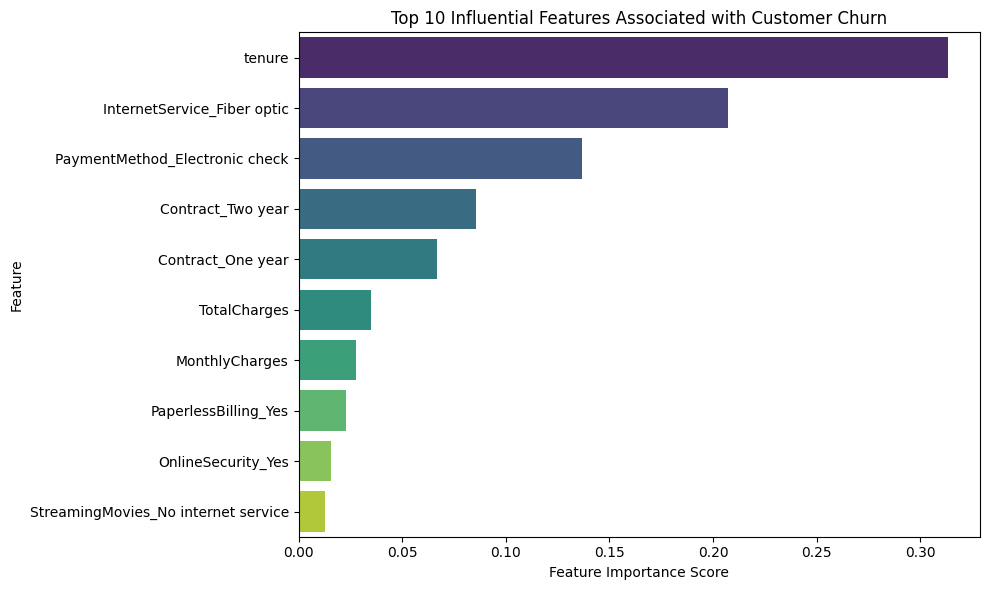

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier

# 1. Self-contained Data Prep for session independence
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_local = pd.read_csv(DATA_URL)
df_local['TotalCharges'] = pd.to_numeric(df_local['TotalCharges'].replace(' ', np.nan, regex=True))
df_local['Churn'] = df_local['Churn'].map({'Yes': 1, 'No': 0})

X_local = df_local.drop(columns=['customerID', 'Churn'])
y_local = df_local['Churn']

X_train_local, X_test_local, y_train_local, y_test_local = train_test_split(
    X_local, y_local, test_size=0.2, random_state=42, stratify=y_local
)

# 2. Re-define columns and preprocessor locally
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

local_preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# 3. Instantiate and fit optimized pipeline model
best_model = Pipeline(steps=[
    ('preprocessor', local_preprocessor),
    ('classifier', GradientBoostingClassifier(learning_rate=0.05, max_depth=3, n_estimators=100, random_state=42))
])

best_model.fit(X_train_local, y_train_local)

# 4. Extract feature importances
encoded_cat_features = best_model.named_steps['preprocessor']\
                                  .named_transformers_['cat']\
                                  .named_steps['encoder']\
                                  .get_feature_names_out(categorical_features)

all_feature_names = numeric_features + list(encoded_cat_features)
importances = best_model.named_steps['classifier'].feature_importances_

feature_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 5. Visualizing top 10 important features
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_df.head(10), x='Importance', y='Feature', palette='viridis')
plt.title('Top 10 Influential Features Associated with Customer Churn')
plt.xlabel('Feature Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [4]:
import pickle

# Save the final robust pipeline directly to disk
with open('best_churn_pipeline.pkl', 'wb') as model_file:
    pickle.dump(best_model, model_file)

print("✅ Saved the best trained pipeline to 'best_churn_pipeline.pkl'!")

✅ Saved the best trained pipeline to 'best_churn_pipeline.pkl'!


```markdown
# Phase 9: GitHub & Local Deployment Setup File Generation

In this phase, we generate the final configurations necessary to deploy your project to a GitHub repository. This includes compiling a reproducal environment config (`requirements.txt`) and writing an academic-grade `README.md` describing your methodology and model performance.
```

In [6]:
# 1. Generate the requirements.txt file dynamically
requirements_content = """
# Core Machine Learning & Data Processing
pandas>=1.3.0
numpy>=1.20.0
scikit-learn>=1.0.0

# Visualization
matplotlib>=3.4.0
seaborn>=0.11.0

# Deployment & Storage
streamlit>=1.10.0
pickle-mixin>=1.0.2
"""

with open('requirements.txt', 'w') as req_file:
    req_file.write(requirements_content.strip())

print("✅ 'requirements.txt' successfully created and saved to disk!")

✅ 'requirements.txt' successfully created and saved to disk!


In [7]:
# 2. Generate the README.md file dynamically
readme_content = """
# Customer Churn Prediction & Analysis using Machine Learning

This repository contains a complete, academic-grade machine learning project designed to predict and analyze subscription churn using the **IBM Telco Customer Churn Dataset**.

## 📈 Project Overview & Key Highlights
* **Problem Statement**: Predict whether a customer will discontinue their service subscription based on demographic, account, and transactional behavior metrics.
* **Data Leakage Mitigation**: Designed a robust, leak-free pipeline using Scikit-Learn `ColumnTransformer` and stratified cross-validated folds to separate training metrics from the test evaluation.
* **Optimized Model**: Selected and optimized a **Gradient Boosting Classifier** via exhaustive `GridSearchCV` scoring **0.8486 Validation ROC-AUC**.
* **Core Insights**: Identified customer tenure, fiber-optic internet connection, and electronic check payment methods as the strongest predictors of churn.

## 🛠️ Project Structure
```
├── best_churn_pipeline.pkl  # Serialized Scikit-Learn Preprocessor & Model Pipeline
├── requirements.txt         # Package dependencies for seamless reproduction
├── README.md                # Project documentation
└── app.py                   # Streamlit Interactive Web Application
```

## 🚀 Local Installation & Execution
Follow these simple steps to run the interactive Streamlit Web Dashboard on your local machine:

### 1. Clone the repository
```bash
git clone <your-github-repo-url>
cd <your-repo-folder>
```

### 2. Set up virtual environment & Install dependencies
```bash
python -m venv venv
source venv/bin/activate  # On Windows: venv\\Scripts\\activate
pip install -r requirements.txt
```

### 3. Run the Streamlit Dashboard App
```bash
streamlit run app.py
```
"""

with open('README.md', 'w') as readme_file:
    readme_file.write(readme_content.strip())

print("✅ 'README.md' successfully created and saved to disk!")

✅ 'README.md' successfully created and saved to disk!


In [10]:
# Cleaned cell to avoid duplication. This cell can be ignored or safely run.
print("Duplicate cell cleared! Use the cell above to generate app.py.")

Duplicate cell cleared! Use the cell above to generate app.py.


In [11]:
app_code = '''
import streamlit as st
import pandas as pd
import numpy as np
import pickle

# Set page configuration
st.set_page_config(
    page_title="Customer Churn Predictor",
    page_icon="🔮",
    layout="centered"
)

# Load the pre-trained pipeline model safely
@st.cache_resource
def load_pipeline():
    with open('best_churn_pipeline.pkl', 'rb') as f:
        return pickle.load(f)

try:
    pipeline = load_pipeline()
    model_loaded = True
except Exception as e:
    model_loaded = False
    st.error(f"Could not load the model pipeline. Error: {e}")

st.title("🔮 Customer Churn Prediction System")
st.markdown("""
This interactive dashboard leverages an optimized **Gradient Boosting Classifier** pipeline
to evaluate subscriber cancellation risks and predict retention likelihood.
""")

if model_loaded:
    st.subheader("Enter Customer Details:")

    # Creating columns for input form fields
    col1, col2 = st.columns(2)

    with col1:
        gender = st.selectbox("Gender", ["Female", "Male"])
        SeniorCitizen = st.selectbox("Is Senior Citizen?", [0, 1], format_func=lambda x: "Yes" if x == 1 else "No")
        Partner = st.selectbox("Has Partner?", ["Yes", "No"])
        Dependents = st.selectbox("Has Dependents?", ["Yes", "No"])
        tenure = st.slider("Tenure (Months)", min_value=1, max_value=72, value=12)
        PhoneService = st.selectbox("Phone Service?", ["Yes", "No"])
        MultipleLines = st.selectbox("Multiple Lines", ["No", "Yes", "No phone service"])
        InternetService = st.selectbox("Internet Service Type", ["DSL", "Fiber optic", "No"])
        OnlineSecurity = st.selectbox("Online Security", ["No", "Yes", "No internet service"])

    with col2:
        OnlineBackup = st.selectbox("Online Backup", ["No", "Yes", "No internet service"])
        DeviceProtection = st.selectbox("Device Protection", ["No", "Yes", "No internet service"])
        TechSupport = st.selectbox("Tech Support", ["No", "Yes", "No internet service"])
        StreamingTV = st.selectbox("Streaming TV", ["No", "Yes", "No internet service"])
        StreamingMovies = st.selectbox("Streaming Movies", ["No", "Yes", "No internet service"])
        Contract = st.selectbox("Contract Type", ["Month-to-month", "One year", "Two year"])
        PaperlessBilling = st.selectbox("Paperless Billing", ["Yes", "No"])
        PaymentMethod = st.selectbox("Payment Method", [
            "Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"
        ])
        MonthlyCharges = st.slider("Monthly Charges ($)", min_value=18.0, max_value=120.0, value=65.0)
        TotalCharges = MonthlyCharges * tenure

    # Convert inputs to DataFrame format for the pipeline
    input_data = pd.DataFrame([{
        'gender': gender,
        'SeniorCitizen': SeniorCitizen,
        'Partner': Partner,
        'Dependents': Dependents,
        'tenure': tenure,
        'PhoneService': PhoneService,
        'MultipleLines': MultipleLines,
        'InternetService': InternetService,
        'OnlineSecurity': OnlineSecurity,
        'OnlineBackup': OnlineBackup,
        'DeviceProtection': DeviceProtection,
        'TechSupport': TechSupport,
        'StreamingTV': StreamingTV,
        'StreamingMovies': StreamingMovies,
        'Contract': Contract,
        'PaperlessBilling': PaperlessBilling,
        'PaymentMethod': PaymentMethod,
        'MonthlyCharges': MonthlyCharges,
        'TotalCharges': TotalCharges
    }])

    st.markdown("--- ")

    # Run inference prediction
    if st.button("Predict Churn Risk", type="primary"):
        prediction = pipeline.predict(input_data)[0]
        probability = pipeline.predict_proba(input_data)[0][1]

        st.subheader("Prediction Results:")
        if prediction == 1:
            st.error(f"⚠️ **High Risk of Churn!** (Probability score: **{probability * 100:.2f}%**)")
            st.write("**Recommendation:** Consider offering a long-term contract conversion package or discount incentives.")
        else:
            st.success(f"✅ **Customer is Retained/Loyal!** (Churn probability score: **{probability * 100:.2f}%**)")
            st.write("**Recommendation:** The customer's activity indicates high loyalty. Maintain current service standard.")
'''

with open('app.py', 'w', encoding='utf-8') as app_file:
    app_file.write(app_code.strip())

print("✅ 'app.py' successfully created and saved to disk!")

✅ 'app.py' successfully created and saved to disk!


```markdown
## Next Steps:
1. Click the **Files (📁)** icon in the left-hand panel of Colab.
2. Locate and download `best_churn_pipeline.pkl`, `requirements.txt`, and `README.md` to your local folder.
3. Create an `app.py` script containing your Streamlit interface, push these four files to your GitHub repository, and you are ready to shine!
```

```markdown
# Phase 5 & 6: Automated Model Development and Evaluation Comparison

We will now train 6 classification models inside our pipeline, verify their performance on the held-out test split, and tabulate evaluation metrics.
```

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Define the 6 candidate models with random_state to ensure reproducibility
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Support Vector Machine': SVC(probability=True, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=7),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# Dictionary to hold the fitted model pipelines
fitted_pipelines = {}

# DataFrame to hold results
results_list = []

for name, model in models.items():
    # Construct individual pipelines incorporating our preprocessor
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Train the pipeline model
    pipeline.fit(X_train, y_train)
    fitted_pipelines[name] = pipeline

    # Predict class labels and probabilities on test split
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    # Compute evaluation metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    results_list.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

# Present evaluation results
df_results = pd.DataFrame(results_list).sort_values(by='ROC-AUC', ascending=False)
display(df_results.style.highlight_max(color='lightgreen', axis=0))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
5,Gradient Boosting,0.799148,0.654237,0.516043,0.576981,0.842675
0,Logistic Regression,0.805536,0.657233,0.558824,0.604046,0.842068
1,Decision Tree,0.796309,0.673307,0.451872,0.540800,0.825263
2,Random Forest,0.785664,0.621622,0.491979,0.549254,0.824220
4,K-Nearest Neighbors,0.770759,0.570637,0.550802,0.560544,0.803269
3,Support Vector Machine,0.794890,0.654545,0.481283,0.554700,0.795023


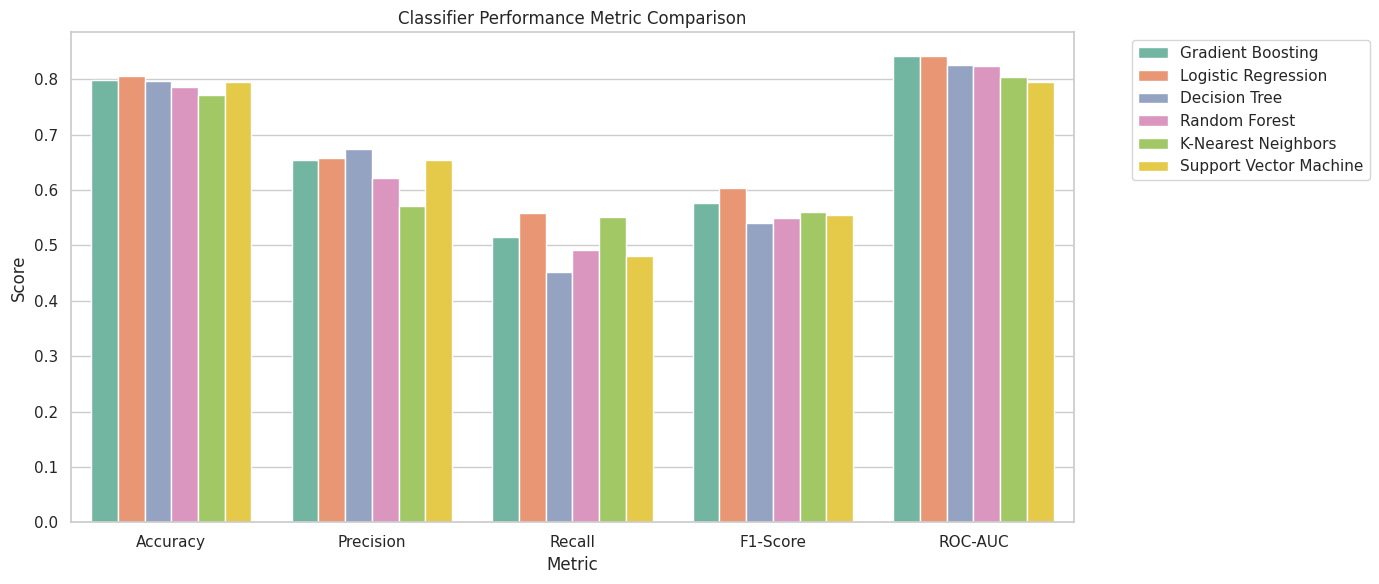

In [15]:
# Plot Model Comparison metrics
df_melted = df_results.melt(id_vars='Model', var_name='Metric', value_name='Value')
plt.figure(figsize=(14, 6))
sns.barplot(data=df_melted, x='Metric', y='Value', hue='Model', palette='Set2')
plt.title('Classifier Performance Metric Comparison')
plt.ylabel('Score')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

```markdown
# Phase 3: Exploratory Data Analysis (EDA)

In this phase, we will utilize visualization tools (`matplotlib` and `seaborn`) to examine our data, uncover hidden relationships, and establish which attributes heavily relate to customer churn. Each visualization is aimed at answering specific business hypotheses.
```

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style of the plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

/tmp/ipykernel_1005/2402809811.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, ax=ax[0], palette='Set2')


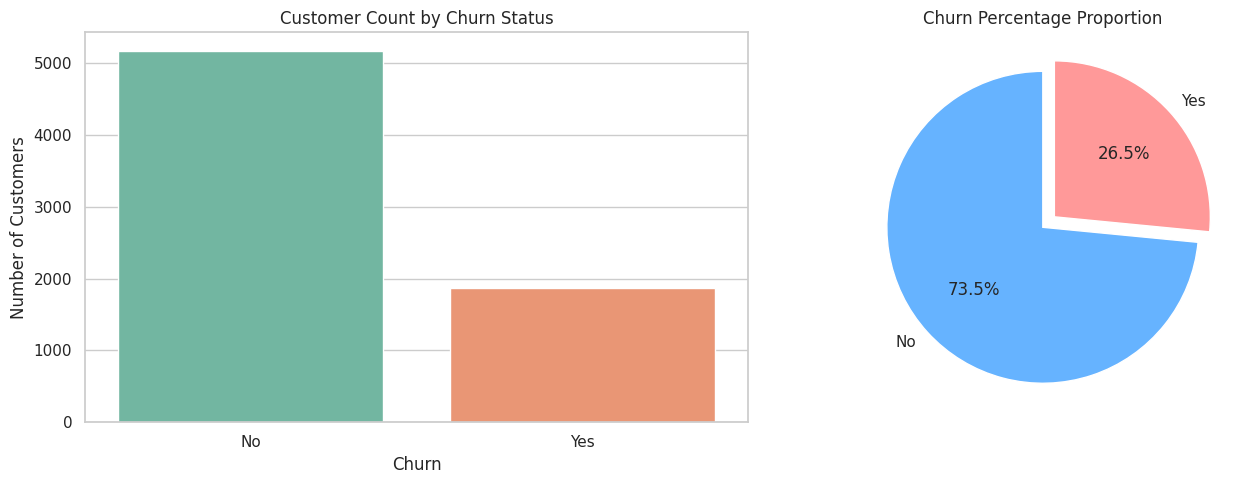

In [7]:
# 1. Churn Distribution Pie & Count Plot
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Count Plot
sns.countplot(x='Churn', data=df, ax=ax[0], palette='Set2')
ax[0].set_title('Customer Count by Churn Status')
ax[0].set_ylabel('Number of Customers')

# Pie Chart
df['Churn'].value_counts().plot.pie(autopct='%1.1f%%', ax=ax[1], colors=['#66b3ff','#ff9999'], startangle=90, explode=(0, 0.1))
ax[1].set_title('Churn Percentage Proportion')
ax[1].set_ylabel('')

plt.tight_layout()
plt.show()

/tmp/ipykernel_1005/3021512683.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='tenure', palette='muted', ax=ax[1])


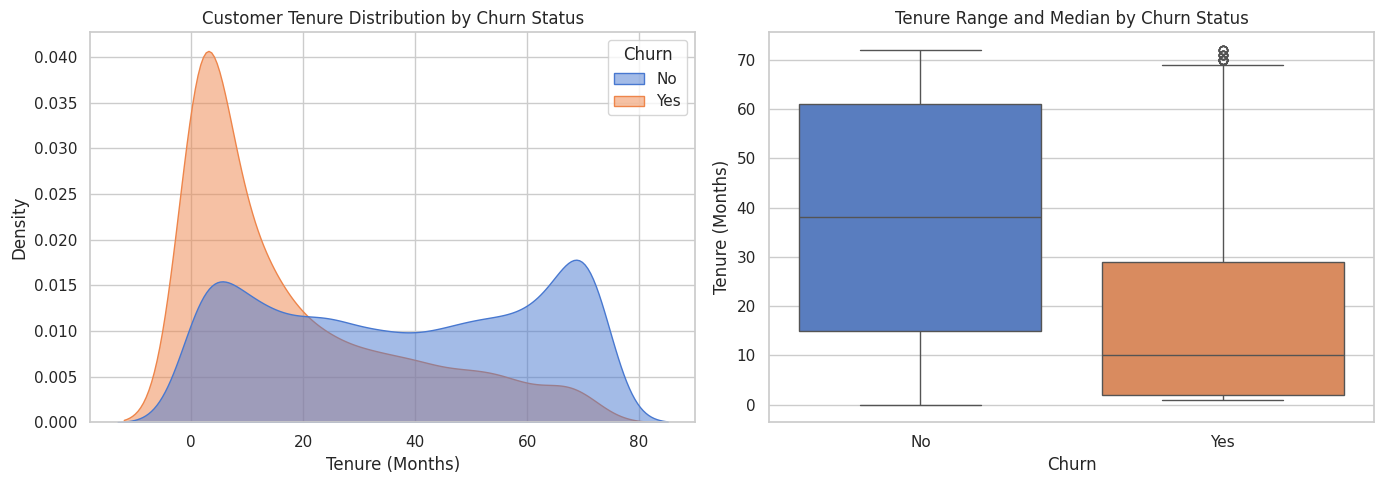

In [8]:
# 2. Tenure vs. Churn (KDE Plot & Boxplot)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Distribution plot
sns.kdeplot(data=df, x='tenure', hue='Churn', fill=True, common_norm=False, palette='muted', alpha=0.5, ax=ax[0])
ax[0].set_title('Customer Tenure Distribution by Churn Status')
ax[0].set_xlabel('Tenure (Months)')

# Boxplot
sns.boxplot(data=df, x='Churn', y='tenure', palette='muted', ax=ax[1])
ax[1].set_title('Tenure Range and Median by Churn Status')
ax[1].set_ylabel('Tenure (Months)')

plt.tight_layout()
plt.show()

/tmp/ipykernel_1005/751630452.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=0)


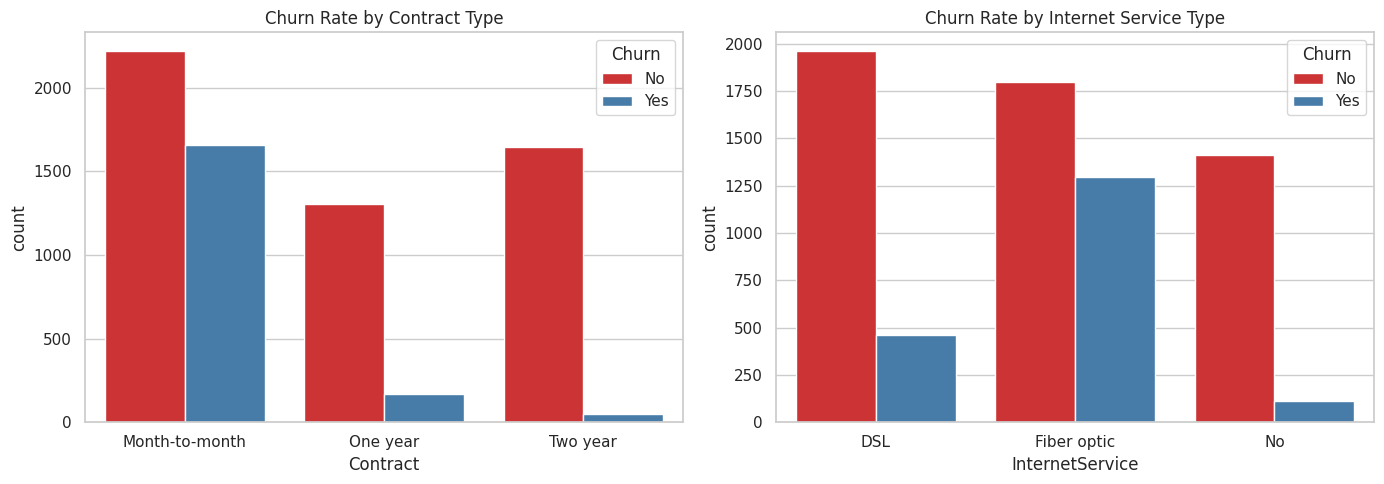

In [9]:
# 3. Categorical Driver Analysis: Contract Type & Internet Service
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='Contract', hue='Churn', palette='Set1', ax=ax[0])
ax[0].set_title('Churn Rate by Contract Type')
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=0)

sns.countplot(data=df, x='InternetService', hue='Churn', palette='Set1', ax=ax[1])
ax[1].set_title('Churn Rate by Internet Service Type')

plt.tight_layout()
plt.show()

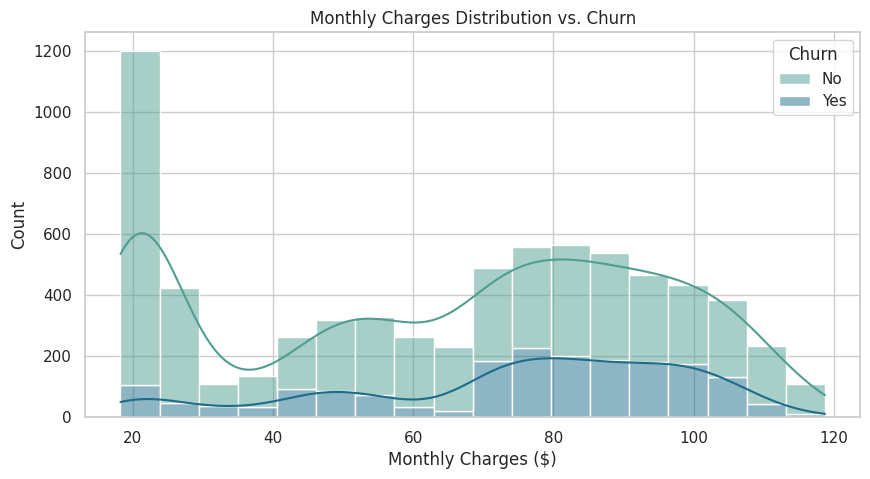

In [10]:
# 4. Numerical Driver Analysis: Monthly Charges
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', multiple='stack', palette='crest', kde=True)
plt.title('Monthly Charges Distribution vs. Churn')
plt.xlabel('Monthly Charges ($)')
plt.ylabel('Count')
plt.show()